<div dir="rtl">

## بخش ۰: پیش‌پردازش داده‌ها و کنترل استقلال مشاهدات
**پوشش‌دهنده: الزام ج.۵ (کنترل مراجعه‌های تکراری) و اصلاح پیش‌پردازش فاز اول**

قبل از شروع محاسبات احتمالی، داده‌های بالینی (`UDS`) و تصویربرداری (`MRI`) را ادغام و تمیزکاری می‌کنیم:

* **کنترل مراجعات تکراری (الزام ج.۵):** بررسی ستون `NACCID` نشان می‌دهد که در هر دو فایل دقیقاً ۱۲۳۷ بیمار یکتا وجود دارد و برای هر فرد فقط یک ویزیت ثبت شده است؛ بنابراین شرط استقلال مشاهدات کاملاً برقرار است.
* **اصلاح مقادیر اعشاری و پرت (طبق راهنمای NACC و نظر TA):** به دلیل اجرای الگوریتم جایگذاری (Imputation) روی دیتاست اولیه، برخی کدهای گمشده (مثل `9`، `88` و `888`) با اعداد واقعی میانگین گرفته شده‌اند. در این فاز به جای گرد کردن مقادیر اعشاری در متغیر اسمی `HYPERTEN`، فقط کدهای معتبر `0` (بدون سابقه)، `1` (فعال) و `2` (قدیمی) را نگه داشتیم و مقادیر اعشاری را به عنوان `NaN` حذف کردیم. همچنین مقادیر خارج از بازه مجاز پزشکی در متغیرهای کمی (`NACCBMI > 100`، `BPSYS > 230`، `MOCATOTS > 30` و `EDUC > 36`) فیلتر شدند تا در نهایت **۱۰۲۲ بیمار با داده‌های کامل و معتبر** باقی بمانند.

</div>

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

uds_df = pd.read_csv('../data/udslong_imputed.csv')
mri_df = pd.read_csv('../data/mriscanclean.csv')

selected_uds = [
    'NACCID',
    'NACCAGE',
    'SEX',
    'EDUC',
    'NACCBMI',
    'BPSYS',
    'HYPERTEN',
    'MOCATOTS',
]
selected_mri = [
    'NACCID',
    'LH_SUPERIORFRONTAL_GVOL',
    'RH_SUPERIORFRONTAL_GVOL',
    'LH_SUPERIORFRONTAL_AVGTH',
    'RH_SUPERIORFRONTAL_AVGTH',
]

df_merged = pd.merge(
    uds_df[selected_uds], mri_df[selected_mri], on='NACCID', how='inner'
)

print(
    f'تعداد کل سطرها: {len(df_merged)} | تعداد بیماران یکتا:'
    f" {df_merged['NACCID'].nunique()}"
)

df_clean = df_merged.copy()
df_clean.loc[df_clean['EDUC'] > 36, 'EDUC'] = np.nan
df_clean.loc[
    (df_clean['NACCBMI'] > 100) | (df_clean['NACCBMI'] < 10), 'NACCBMI'
] = np.nan
df_clean.loc[(df_clean['BPSYS'] > 230) | (df_clean['BPSYS'] < 70), 'BPSYS'] = (
    np.nan
)
df_clean.loc[
    (df_clean['MOCATOTS'] > 30) | (df_clean['MOCATOTS'] < 0), 'MOCATOTS'
] = np.nan
df_clean.loc[~df_clean['HYPERTEN'].isin([0.0, 1.0, 2.0]), 'HYPERTEN'] = np.nan

df_final = df_clean.dropna().reset_index(drop=True)
df_final['HYPERTEN'] = df_final['HYPERTEN'].astype(int)
df_final['SEX'] = df_final['SEX'].astype(int)

print(f'تعداد نهایی بیماران پس از پاکسازی کامل: {len(df_final)}')

تعداد کل سطرها: 1237 | تعداد بیماران یکتا: 1237
تعداد نهایی بیماران پس از پاکسازی کامل: 1022


<div dir="rtl">

## بخش ۱: تعریف رویدادها و متغیرهای تصادفی
**پوشش‌دهنده: تسک ۱ و پیش‌نیاز الزامات ج.۱ و ج.۳**

در این بخش، با توجه به سؤال اصلی پروژه، رویدادهای تصادفی و متغیرهای کمی را روی ۱۰۲۲ بیمار مستقل تعریف می‌کنیم:

**الف) رویدادهای تصادفی (از دو وجه UDS و MRI):**
* **رویداد $A$ (پرفشاری خون فعال - از UDS):** بیمار دارای سابقه فعال یا اخیر فشار خون بالا باشد (`HYPERTEN == 1`).
* **رویداد $B$ (اختلال شناختی - از UDS):** نمره تست شناختی MoCA بیمار کمتر از ۲۶ باشد (`MOCATOTS < 26` که مرز استاندارد پزشکی برای تشخیص افت شناختی است).
* **رویداد $C$ (کاهش حجم قشر پیشانی چپ - از MRI):** حجم ماده خاکستری ناحیه پیشانی فوقانی چپ (`LH_SUPERIORFRONTAL_GVOL`) کمتر از میانه کل بیماران (یعنی کمتر از ۲۱۶۱۶.۵ میلی‌متر مکعب) باشد.

**ب) متغیرهای تصادفی:**
* **متغیر تصادفی گسسته ($X$):** تعداد بیماران دارای اختلال شناختی (وقوع رویداد $B$) در یک نمونه تصادفی $n$ تایی از بیماران.
* **متغیرهای تصادفی پیوسته:** نمره شناختی (`MOCATOTS`) و شاخص توده بدنی (`NACCBMI`) از بخش بالینی، و حجم ماده خاکستری پیشانی فوقانی چپ (`LH_SUPERIORFRONTAL_GVOL`) از بخش تصویربرداری.

</div>

In [3]:
median_lhgvol = df_final['LH_SUPERIORFRONTAL_GVOL'].median()

df_final['Event_A_Hyper'] = df_final['HYPERTEN'] == 1
df_final['Event_B_CogImp'] = df_final['MOCATOTS'] < 26
df_final['Event_C_LowVol'] = df_final['LH_SUPERIORFRONTAL_GVOL'] < median_lhgvol

events_summary = pd.DataFrame({
    'رویداد': [
        'A: پرفشاری خون فعال (UDS)',
        'B: اختلال شناختی MoCA < 26 (UDS)',
        'C: حجم قشر پیشانی زیر میانه (MRI)',
    ],
    'تعداد وقوع': [
        df_final['Event_A_Hyper'].sum(),
        df_final['Event_B_CogImp'].sum(),
        df_final['Event_C_LowVol'].sum(),
    ],
    'احتمال تجربی': [
        df_final['Event_A_Hyper'].mean().round(4),
        df_final['Event_B_CogImp'].mean().round(4),
        df_final['Event_C_LowVol'].mean().round(4),
    ],
})

display(events_summary)

,رویداد,تعداد وقوع,احتمال تجربی
0,A: پرفشاری خون فعال (UDS),396,0.3875
1,B: اختلال شناختی MoCA < 26 (UDS),534,0.5225
2,C: حجم قشر پیشانی زیر میانه (MRI),511,0.5000


<div dir="rtl">

## بخش ۲: احتمال‌های حاشیه‌ای، مشترک، شرطی و بررسی استقلال
**پوشش‌دهنده: تسک ۲ + تسک ۳ + تسک ۴ + الزام ج.۱ + الزام ج.۳**

در این بخش با استفاده از فراوانی‌های تجربی روی ۱۰۲۲ بیمار یکتا، احتمال‌های حاشیه‌ای، مشترک و شرطی را بین متغیرهای بالینی (`UDS`) و تصویربرداری (`MRI`) بررسی می‌کنیم:

* **احتمال‌های حاشیه‌ای و مشترک (تسک ۲ و الزام ج.۳):** احتمال وقوع رویدادها را به‌صورت تکی و هم‌زمان محاسبه می‌کنیم.
* **احتمال شرطی (تسک ۳ و الزام ج.۱):** احتمال اختلال شناختی ($B$) را در زیرگروه‌های پرفشاری خون ($A$) و کاهش حجم قشر پیشانی ($C$) مقایسه می‌کنیم.
* **بررسی استقلال (تسک ۴):** با مقایسه $P(B | A)$ با $P(B)$ و $P(B  |  C)$ با $P(B)$، سازگاری داده با فرض استقلال را بدون آزمون فرض رسمی می‌سنجیم.

</div>

,کمیت,مقدار تجربی
0,P(A) پرفشاری فعال,0.3875
1,P(B) اختلال شناختی,0.5225
2,P(C) حجم MRI زیر میانه,0.5000
3,P(A ∩ B) مشترک UDS,0.2339
4,P(B ∩ C) مشترک UDS+MRI,0.2926
5,P(B | A),0.6035
6,P(B | ¬A),0.4712
7,P(B | C),0.5851
8,P(B | ¬C),0.4599


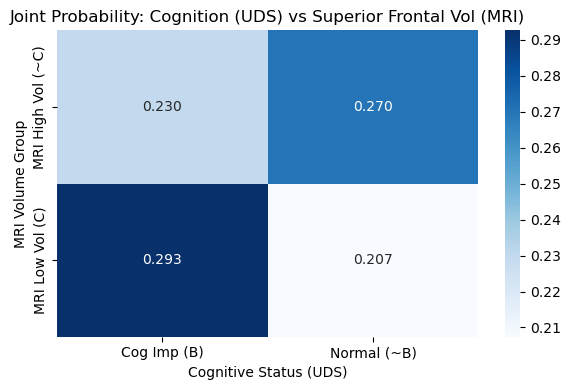

In [10]:
p_a = df_final['Event_A_Hyper'].mean()
p_b = df_final['Event_B_CogImp'].mean()
p_c = df_final['Event_C_LowVol'].mean()

p_ab = (df_final['Event_A_Hyper'] & df_final['Event_B_CogImp']).mean()
p_bc = (df_final['Event_B_CogImp'] & df_final['Event_C_LowVol']).mean()

p_b_given_a = df_final.loc[df_final['Event_A_Hyper'], 'Event_B_CogImp'].mean()
p_b_given_not_a = df_final.loc[~df_final['Event_A_Hyper'], 'Event_B_CogImp'].mean()

p_b_given_c = df_final.loc[df_final['Event_C_LowVol'], 'Event_B_CogImp'].mean()
p_b_given_not_c = df_final.loc[~df_final['Event_C_LowVol'], 'Event_B_CogImp'].mean()

summary_prob = pd.DataFrame({
    'کمیت': [
        'P(A) پرفشاری فعال',
        'P(B) اختلال شناختی',
        'P(C) حجم MRI زیر میانه',
        'P(A ∩ B) مشترک UDS',
        'P(B ∩ C) مشترک UDS+MRI',
        'P(B | A)',
        'P(B | ¬A)',
        'P(B | C)',
        'P(B | ¬C)',
    ],
    'مقدار تجربی': np.round(
        [
            p_a,
            p_b,
            p_c,
            p_ab,
            p_bc,
            p_b_given_a,
            p_b_given_not_a,
            p_b_given_c,
            p_b_given_not_c,
        ],
        4,
    ),
})
display(summary_prob)

ct = pd.crosstab(
    df_final['Event_C_LowVol'].map({True: 'MRI Low Vol (C)', False: 'MRI High Vol (~C)'}),
    df_final['Event_B_CogImp'].map({True: 'Cog Imp (B)', False: 'Normal (~B)'}),
    normalize=True,
)
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt='.3f', cmap='Blues')
plt.title('Joint Probability: Cognition (UDS) vs Superior Frontal Vol (MRI)')
plt.xlabel('Cognitive Status (UDS)')
plt.ylabel('MRI Volume Group')
plt.tight_layout()
plt.show()

<div dir="rtl">

### تفسیر احتمال شرطی و استقلال
- احتمال حاشیه‌ای اختلال شناختی برابر $P(B) \approx 0.5225$ است؛ با شرط کردن روی $A$ به $P(B | A) \approx 0.6035$ می‌رسد و در حالت $\neg A$ برابر $P(B | \neg A) \approx 0.4712$ است.
- با شرط کردن روی $C$، احتمال اختلال شناختی به $P(B \ | \ C) \approx 0.5851$ می‌رسد و در حالت $\neg C$ برابر $P(B \ | \ \neg C) \approx 0.4599$ است.
- چون $P(B | A)$ و $P(B \ | \ C)$ با $P(B)$ یکسان نیستند، داده با فرض استقلال کامل سازگار به نظر نمی‌رسد؛ اما این صرفاً مشاهده ارتباط احتمالی است و به معنی علیت نیست.

</div>

<div dir="rtl">

## بخش ۳: توزیع گسسته و تقریب مدل دوجمله‌ای
**پوشش‌دهنده: تسک ۵**

متغیر تصادفی گسسته $X$ را تعداد بیماران دارای اختلال شناختی (`Event_B_CogImp`) در زیرنمونه‌های تصادفی بدون جای‌گذاری با اندازه ثابت $n = 20$ تعریف می‌کنیم و توزیع تجربی آن را با مدل $\text{Binomial}(n, p)$ مقایسه می‌کنیم (با $\hat{p} = \hat{P}(B) \approx 0.5225$).

</div>

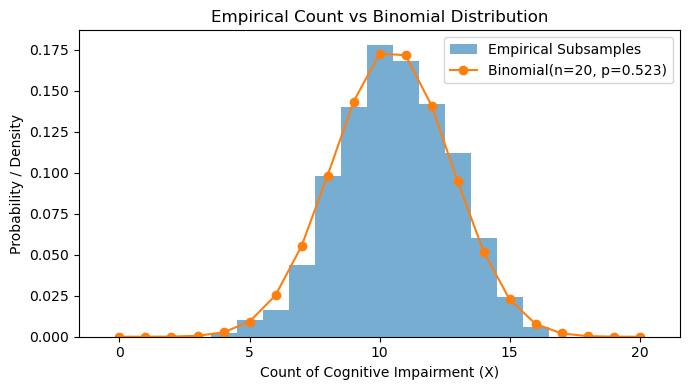

Empirical mean: 10.590 | Theoretical np: 10.450
Empirical var: 4.687 | Theoretical np(1-p): 4.990


In [11]:
rng = np.random.default_rng(42)
n = 20
num_samples = 500
p_hat = df_final['Event_B_CogImp'].mean()
b_values = df_final['Event_B_CogImp'].to_numpy()

emp_counts = np.array(
    [rng.choice(b_values, size=n, replace=False).sum() for _ in range(num_samples)]
)

k_grid = np.arange(0, n + 1)
theo_pmf = stats.binom.pmf(k_grid, n=n, p=p_hat)

plt.figure(figsize=(7, 4))
plt.hist(
    emp_counts,
    bins=np.arange(-0.5, n + 1.5, 1),
    density=True,
    alpha=0.6,
    label='Empirical Subsamples',
)
plt.plot(k_grid, theo_pmf, 'o-', label=f'Binomial(n={n}, p={p_hat:.3f})')
plt.title('Empirical Count vs Binomial Distribution')
plt.xlabel('Count of Cognitive Impairment (X)')
plt.ylabel('Probability / Density')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Empirical mean: {emp_counts.mean():.3f} | Theoretical np: {n * p_hat:.3f}')
print(
    f'Empirical var: {emp_counts.var(ddof=1):.3f} | Theoretical np(1-p): {n * p_hat * (1 - p_hat):.3f}'
)

<div dir="rtl">

### بررسی فرض‌های مدل دوجمله‌ای
- میانگین تجربی ($\approx 10.59$) و واریانس تجربی ($\approx 4.69$) نزدیک به مقادیر نظری دوجمله‌ای ($np \approx 10.45$ و $np(1-p) \approx 4.99$) هستند و تقریب دوجمله‌ای تصویر قابل قبولی از شمارش در زیرنمونه‌ها می‌دهد.
- با این حال فرض‌های سخت‌گیرانه دوجمله‌ای به‌طور کامل برقرار نیست: اول اینکه نمونه‌گیری از میان ۱۰۲۲ بیمار **بدون جای‌گذاری** انجام شده (در عمل هایپرژئومتریک است، هرچند چون $n=20$ نسبت به $N=1022$ کوچک است اختلافش کم است) و دوم اینکه احتمال $p$ برای همه افراد یکسان نیست چون سن، تحصیلات و سابقه بالینی روی افت شناختی اثر دارند.

</div>

<div dir="rtl">

## بخش ۴: توزیع متغیرهای پیوسته، امید ریاضی، واریانس و تقریب نرمال
**پوشش‌دهنده: تسک ۶ + تسک ۷ + الزام ج.۲**

در این بخش امید ریاضی تجربی (میانگین)، واریانس، انحراف معیار، چولگی و نقاط دورافتاده را برای متغیرهای کمی بالینی (`MOCATOTS`، `NACCBMI`، `BPSYS`) و تصویربرداری (`LH_SUPERIORFRONTAL_GVOL`، `LH_SUPERIORFRONTAL_AVGTH`) روی ۱۰۲۲ بیمار بررسی می‌کنیم و تناسب تقریب نرمال را با هیستوگرام و Q-Q Plot می‌سنجیم.

</div>

,متغیر,میانگین (امید ریاضی),واریانس,انحراف معیار,میانه,چولگی,نقاط دورافتاده (IQR)
0,MOCATOTS,24.4742,1.853420e+01,4.3051,25.600,-1.8531,59
1,NACCBMI,27.4178,2.636030e+01,5.1342,26.500,0.9138,25
2,BPSYS,133.3969,3.242990e+02,18.0083,132.000,0.5291,10
3,LH_SUPERIORFRONTAL_GVOL,21689.2427,9.788054e+06,3128.5865,21616.500,-1.0703,22
4,LH_SUPERIORFRONTAL_AVGTH,2.4912,2.070000e-02,0.1439,2.499,-2.5962,22


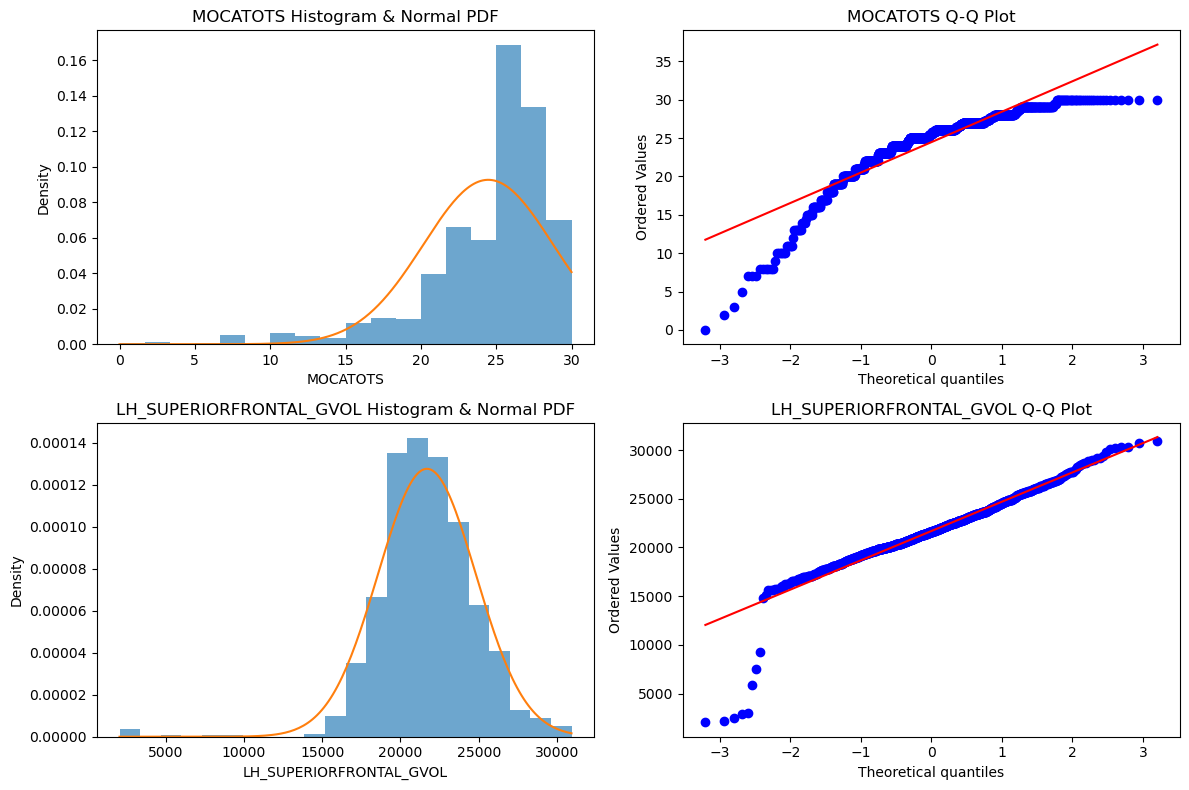

In [12]:
vars_cont = [
    'MOCATOTS',
    'NACCBMI',
    'BPSYS',
    'LH_SUPERIORFRONTAL_GVOL',
    'LH_SUPERIORFRONTAL_AVGTH',
]

rows = []
for col in vars_cont:
    s = df_final[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    rows.append({
        'متغیر': col,
        'میانگین (امید ریاضی)': round(s.mean(), 4),
        'واریانس': round(s.var(ddof=1), 4),
        'انحراف معیار': round(s.std(ddof=1), 4),
        'میانه': round(s.median(), 4),
        'چولگی': round(s.skew(), 4),
        'نقاط دورافتاده (IQR)': n_out,
    })

cont_summary = pd.DataFrame(rows)
display(cont_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

s_moca = df_final['MOCATOTS']
axes[0, 0].hist(s_moca, bins=18, density=True, alpha=0.65)
x_moca = np.linspace(s_moca.min(), s_moca.max(), 200)
axes[0, 0].plot(
    x_moca, stats.norm.pdf(x_moca, s_moca.mean(), s_moca.std(ddof=1)), '-'
)
axes[0, 0].set_title('MOCATOTS Histogram & Normal PDF')
axes[0, 0].set_xlabel('MOCATOTS')
axes[0, 0].set_ylabel('Density')

stats.probplot(s_moca, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('MOCATOTS Q-Q Plot')

s_vol = df_final['LH_SUPERIORFRONTAL_GVOL']
axes[1, 0].hist(s_vol, bins=22, density=True, alpha=0.65)
x_vol = np.linspace(s_vol.min(), s_vol.max(), 200)
axes[1, 0].plot(x_vol, stats.norm.pdf(x_vol, s_vol.mean(), s_vol.std(ddof=1)), '-')
axes[1, 0].set_title('LH_SUPERIORFRONTAL_GVOL Histogram & Normal PDF')
axes[1, 0].set_xlabel('LH_SUPERIORFRONTAL_GVOL')
axes[1, 0].set_ylabel('Density')

stats.probplot(s_vol, dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('LH_SUPERIORFRONTAL_GVOL Q-Q Plot')

plt.tight_layout()
plt.show()

<div dir="rtl">

### تفسیر امید ریاضی، واریانس و تقریب نرمال (تسک ۶، ۷ و الزام ج.۲)
- میانگین و واریانس نشان‌دهنده مرکز و پراکندگی هر شاخص در نمونه ۱۰۲۲ نفری هستند؛ مثلاً برای `MOCATOTS` میانگین حدود $24.47$ و واریانس حدود $18.53$ است و برای `LH_SUPERIORFRONTAL_GVOL` میانگین حدود $21689.24$ و واریانس حدود $9.79 \times 10^6$ به دست می‌آید.
- تقریب نرمال برای هیچ‌کدام از این متغیرها کاملاً دقیق نیست؛ `MOCATOTS` به دلیل سقف نمره $30$ و تجمع نمرات بالا چولگی منفی قابل‌توجه ($\approx -1.85$) و انحراف در دم چپ Q-Q Plot دارد و `LH_SUPERIORFRONTAL_GVOL` نیز با چولگی منفی ($\approx -1.07$) و نقاط دورافتاده در دم پایین از تقریب نرمال فاصله می‌گیرد.

</div>

<div dir="rtl">

## بخش ۵: تحلیل دو متغیر تصادفی، نمودار پراکنش و کوواریانس بین شناخت و تصویربرداری
**پوشش‌دهنده: تسک ۸ + الزام ج.۴**

در این بخش رابطه دو متغیر تصادفی کمی بین وجه بالینی/شناختی (`MOCATOTS`، `NACCBMI`، `BPSYS`) و وجه تصویربرداری (`LH_SUPERIORFRONTAL_GVOL`، `LH_SUPERIORFRONTAL_AVGTH`) را روی ۱۰۲۲ بیمار یکتا با نمودار پراکنش (Scatter Plot) و ماتریس کوواریانس تجربی بررسی می‌کنیم.

</div>

,MOCATOTS,NACCBMI,BPSYS,LH_SUPERIORFRONTAL_GVOL,LH_SUPERIORFRONTAL_AVGTH
MOCATOTS,18.5342,-0.0942,-11.6303,2.790473e+03,0.1049
NACCBMI,-0.0942,26.3603,13.5231,4.072734e+02,0.0307
BPSYS,-11.6303,13.5231,324.2990,-2.433724e+03,-0.1393
LH_SUPERIORFRONTAL_GVOL,2790.4727,407.2734,-2433.7244,9.788054e+06,149.8891
LH_SUPERIORFRONTAL_AVGTH,0.1049,0.0307,-0.1393,1.498891e+02,0.0207


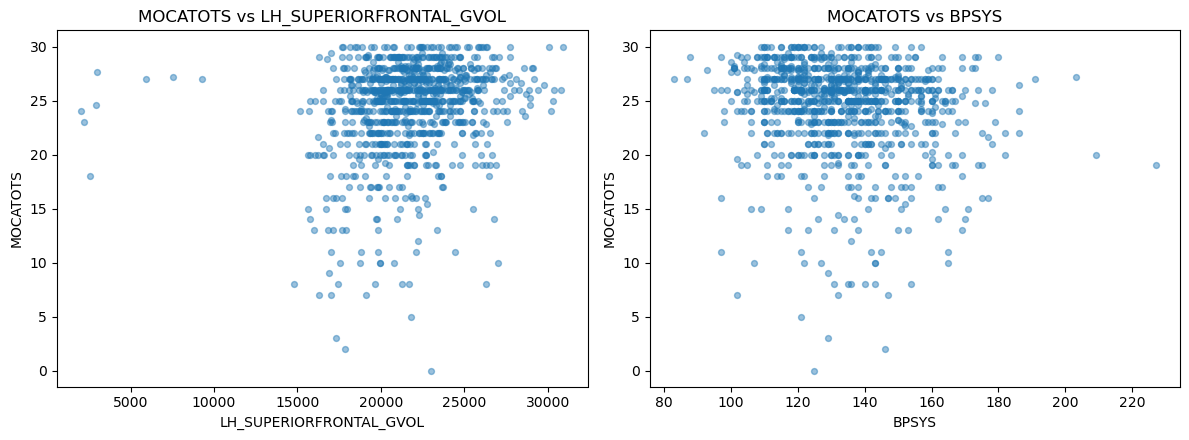

In [13]:
cov_cols = [
    'MOCATOTS',
    'NACCBMI',
    'BPSYS',
    'LH_SUPERIORFRONTAL_GVOL',
    'LH_SUPERIORFRONTAL_AVGTH',
]
cov_matrix = df_final[cov_cols].cov()
display(cov_matrix.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(
    df_final['LH_SUPERIORFRONTAL_GVOL'], df_final['MOCATOTS'], alpha=0.45, s=18
)
axes[0].set_title('MOCATOTS vs LH_SUPERIORFRONTAL_GVOL')
axes[0].set_xlabel('LH_SUPERIORFRONTAL_GVOL')
axes[0].set_ylabel('MOCATOTS')

axes[1].scatter(df_final['BPSYS'], df_final['MOCATOTS'], alpha=0.45, s=18)
axes[1].set_title('MOCATOTS vs BPSYS')
axes[1].set_xlabel('BPSYS')
axes[1].set_ylabel('MOCATOTS')

plt.tight_layout()
plt.show()

<div dir="rtl">

### تفسیر نمودار پراکنش و کوواریانس (تسک ۸ و الزام ج.۴)
- کوواریانس تجربی بین `MOCATOTS` و `LH_SUPERIORFRONTAL_GVOL` مثبت و حدود $+2790.47$ است که هم‌جهتی ضعیف میان حجم ماده خاکستری پیشانی فوقانی و نمره شناختی را نشان می‌دهد.
- کوواریانس بین `MOCATOTS` و `BPSYS` منفی و حدود $-11.63$ است، اما پراکندگی نقاط در نمودار زیاد است و الگوی خطی فشرده‌ای دیده نمی‌شود.
- این کوواریانس و پراکندگی فقط جهت و هم‌حرکتی تجربی را توصیف می‌کنند و به هیچ وجه به معنای علیت یا آزمون رسمی همبستگی نیستند (استنباط همبستگی در فاز چهارم بررسی می‌شود).

</div>